# Experiment 025: 7B exposure sweep ends analysis

Experiment 025 completes the base MC-SFT exposure curve at 7B:

- p2 and p32 were trained and evaluated here with seeds 0 to 2
- p8 reuses the three 014 endpoints
- p16 reuses the three 024 endpoints

The registered comparisons are p2 minus p8 and p32 minus p8. The four point curve is descriptive because each exposure uses its own linear decay schedule. It therefore measures the training budget under the method as practised, not exposure with one shared schedule.


In [1]:
# load the completed arms and the registered references
import json
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import numpy as np
import pandas as pd
from IPython.display import display
get_ipython().run_line_magic('matplotlib', 'inline')

ROOT = Path.cwd()
while not (ROOT / 'config.py').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / 'config.py').exists():
    raise FileNotFoundError('repository root containing config.py was not found')
sys.path.insert(0, str(ROOT))

from analysis.plotting import heatmap_text_color
from analysis.stats import align_pred_rows
from data.subjects import TIERS as VALIDATED_TIERS

RES = ROOT / 'results'
FIG = ROOT / 'analysis' / 'figures' / '025_1'
FIG.mkdir(parents=True, exist_ok=True)

SEEDS = (0, 1, 2)
EXPOSURES = ('p2', 'p8', 'p16', 'p32')
NEW_EXPOSURES = ('p2', 'p32')
PASSES = {'p2': 2, 'p8': 8, 'p16': 16, 'p32': 32}
STEPS = {'p2': 31, 'p32': 490}
TIERS = ['easy', 'medium', 'hard']
GROUPS = TIERS + ['overall']
TIER_LOOKUP = {
    subject: tier
    for tier, subjects in VALIDATED_TIERS.items()
    for subject in subjects
}
SUBJECTS = [
    subject
    for tier in TIERS
    for subject in VALIDATED_TIERS[tier]
]

PATHS = {
    'p2': {
        seed: RES / f'025_p2_COLAB_FULL_B7_sft_only_seed{seed}'
        for seed in SEEDS
    },
    'p8': {
        seed: RES / f'014_p8_COLAB_FULL_B7_sft_only_seed{seed}'
        for seed in SEEDS
    },
    'p16': {
        seed: RES / f'024_p16_COLAB_FULL_B7_sft_only_seed{seed}'
        for seed in SEEDS
    },
    'p32': {
        seed: RES / f'025_p32_COLAB_FULL_B7_sft_only_seed{seed}'
        for seed in SEEDS
    },
}

COLORS = {
    'p2': '#4C78A8',
    'p8': '#F58518',
    'p16': '#54A24B',
    'p32': '#E45756',
}
SCALE_COLORS = {
    '0.5B': '#4C78A8',
    '1.5B': '#F58518',
    '3B': '#54A24B',
    '7B': '#E45756',
}

plt.style.use('seaborn-v0_8-whitegrid')

def jload(path):
    with open(path) as handle:
        return json.load(handle)

def jsonl(path):
    with open(path) as handle:
        rows = [json.loads(line) for line in handle if line.strip()]
    return [
        {**row, 'tier': row.get('tier', TIER_LOOKUP[row['subject']])}
        for row in rows
    ]

def save(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=300, bbox_inches='tight')
    print('saved', name)

def accuracy(rows):
    return float(np.mean([bool(row['correct']) for row in rows]))

def nonfinite_paths(value, path='root'):
    found = []
    if isinstance(value, dict):
        for key, item in value.items():
            found.extend(nonfinite_paths(item, f'{path}/{key}'))
    elif isinstance(value, list):
        for index, item in enumerate(value):
            found.extend(nonfinite_paths(item, f'{path}/{index}'))
    elif isinstance(value, float) and not math.isfinite(value):
        found.append(path)
    return found

def load_sft(path, include_train=False):
    output = {
        'eval': jload(path / 'sft_eval.json'),
        'probe': jload(path / 'sft_logprob.json'),
        'preds': jsonl(path / 'sft_preds.jsonl'),
        'probe_preds': jsonl(path / 'sft_logprob_preds.jsonl'),
    }
    if include_train:
        output.update({
            'train': jload(path / 'sft_trainlog.json'),
            'manifest': jload(path / 'manifest.json'),
            'eval_manifest': jload(path / 'sft_eval_manifest.json'),
            'source': jload(path / 'source_binding.json'),
            'eval_binding': jload(path / 'sft_eval_binding.json'),
            'log': (path / 'run.log').read_text(),
        })
    return output

RUNS = {
    exposure: {
        seed: load_sft(
            path,
            include_train=exposure in NEW_EXPOSURES,
        )
        for seed, path in paths.items()
    }
    for exposure, paths in PATHS.items()
}
REGISTERED = jload(RES / '025_comparison_summary.json')

print('loaded the complete four point 7B exposure curve')
print('figures ->', FIG.relative_to(ROOT))


loaded the complete four point 7B exposure curve
figures -> analysis/figures/025_1


## 1. Completion and run health

These checks run before any result is plotted. They cover the six new arms, exact step coverage, the registered learning-rate schedules, both evaluation modes, hardware, precision, fallback settings, prediction counts, finite values and interruption markers.


In [2]:
# verify all six new arms before using their results
health_rows = []
bad_terms = ['traceback', 'out of memory', 'protocol abort', 'keyboardinterrupt']

assert REGISTERED['binding'] is True
assert {
    (arm['exposure'], arm['seed'])
    for arm in REGISTERED['arms']
} == {
    (exposure, seed)
    for exposure in NEW_EXPOSURES
    for seed in SEEDS
}

for exposure in NEW_EXPOSURES:
    for seed, data in RUNS[exposure].items():
        train_rows = [
            row for row in data['train']
            if 'loss' in row and 'step' in row
        ]
        steps = [row['step'] for row in train_rows]
        learning_rates = np.asarray([
            row['learning_rate'] for row in train_rows
        ])
        expected_steps = STEPS[exposure]
        manifest = data['manifest']
        config = manifest['config']
        invalid = nonfinite_paths(data['train'])
        invalid += nonfinite_paths(data['eval'])
        invalid += nonfinite_paths(data['probe'])

        assert steps == list(range(1, expected_steps + 1))
        assert len(set(steps)) == expected_steps
        assert np.isclose(learning_rates[0], 1e-4)
        assert np.all(np.diff(learning_rates) <= 1e-12)
        assert learning_rates[-1] <= 1.1e-4 / expected_steps
        assert data['eval']['n_items'] == 1884
        assert data['probe']['n_items'] == 1884
        assert len(data['preds']) == 1884
        assert len(data['probe_preds']) == 1884
        assert data['eval_manifest']['completed'] is True
        assert data['eval_manifest']['seed_override'] == seed
        assert data['source']['exposure'] == exposure
        assert data['source']['seed'] == seed
        assert len(data['source']['execution_protocol_sha256']) == 64
        assert manifest['model_id'] == 'Qwen/Qwen2.5-7B'
        assert manifest['seed'] == seed
        assert manifest['resolved_dtype'] == 'bfloat16'
        assert 'A100-SXM4-80GB' in manifest['gpu']['device']
        assert config['train']['max_steps'] == expected_steps
        assert config['train']['sft_data'] == 'mmlu_mc'
        assert config['train']['sft_batch_size'] == 4
        assert config['train']['sft_grad_accum'] == 4
        assert config['exec']['gradient_checkpointing'] is False
        assert config['exec']['allow_oom_fallback'] is False
        assert config['eval']['skip_generative'] is True
        assert set(data['eval_binding']) == {
            'adapter_model.safetensors',
            'adapter_config.json',
            'adapter_base.json',
        }
        assert all(
            isinstance(value, str) and len(value) == 64
            for value in data['eval_binding'].values()
        )
        assert not invalid
        assert not any(term in data['log'].lower() for term in bad_terms)

        health_rows.append({
            'exposure': exposure,
            'seed': seed,
            'steps': len(train_rows),
            'first LR': learning_rates[0],
            'last LR': learning_rates[-1],
            'generative items': data['eval']['n_items'],
            'probe items': data['probe']['n_items'],
            'format compliance': data['eval']['format_compliance'],
            'extraction failures': data['eval']['extraction_failure_rate'],
            'peak VRAM GB': manifest['gpu']['peak_vram_gb'],
            'train minutes': manifest['timings_sec']['sft_train'] / 60,
            'eval minutes': data['eval_manifest']['timings_sec']['sft_eval'] / 60,
            'git commit': manifest['git']['commit'][:8],
        })

health_tbl = pd.DataFrame(health_rows).set_index(['exposure', 'seed'])
display(health_tbl.round(4))
print('all six new arms passed the completion checks')


steps  first LR  last LR  generative items  probe items  \
exposure seed                                                            
p2       0        31    0.0001      0.0              1884         1884   
         1        31    0.0001      0.0              1884         1884   
         2        31    0.0001      0.0              1884         1884   
p32      0       490    0.0001      0.0              1884         1884   
         1       490    0.0001      0.0              1884         1884   
         2       490    0.0001      0.0              1884         1884   

               format compliance  extraction failures  peak VRAM GB  \
exposure seed                                                         
p2       0                1.0000                  0.0        33.301   
         1                1.0000                  0.0        33.301   
         2                0.9942                  0.0        33.301   
p32      0                1.0000                  0.0        26.785   
         1                1.0000                  0.0        26.785   
         2                1.0000                  0.0        26.785   

               train minutes  eval minutes git commit  
exposure seed                                          
p2       0            2.2100        5.5692   34a26779  
         1            1.9407        5.6005   8f0f87ee  
         2            1.3418        7.6025   8f0f87ee  
p32      0            9.7907        5.4399   34a26779  
         1            9.7140        5.4101   8f0f87ee  
         2            9.9175        5.4334   8f0f87ee

all six new arms passed the completion checks


## 2. Supervised training behaviour


saved fig01_training_health


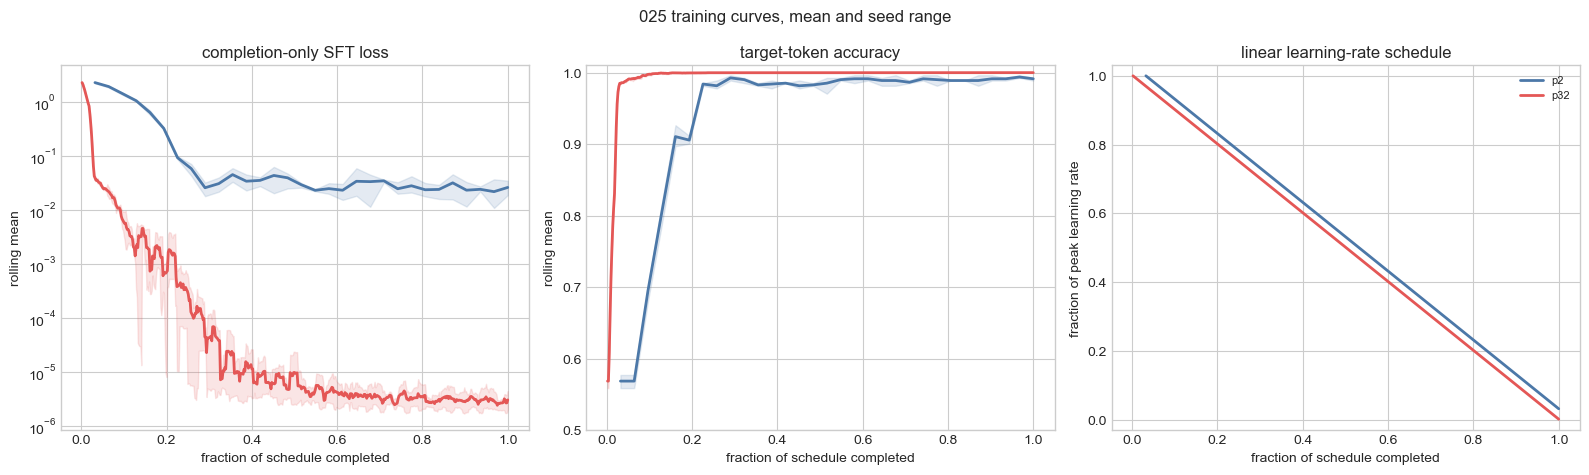

In [3]:
# compare the two new schedules on normalised training progress
train_rows = []
for exposure in NEW_EXPOSURES:
    for seed, data in RUNS[exposure].items():
        for row in data['train']:
            if 'loss' not in row or 'step' not in row:
                continue
            train_rows.append({
                'exposure': exposure,
                'seed': seed,
                'step': row['step'],
                'progress': row['step'] / STEPS[exposure],
                'loss': row['loss'],
                'token accuracy': row['mean_token_accuracy'],
                'learning rate fraction': row['learning_rate'] / 1e-4,
            })
train_tbl = pd.DataFrame(train_rows)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for exposure in NEW_EXPOSURES:
    subset = train_tbl[train_tbl['exposure'] == exposure]
    window = max(1, STEPS[exposure] // 50)
    for metric, ax in [
        ('loss', axes[0]),
        ('token accuracy', axes[1]),
        ('learning rate fraction', axes[2]),
    ]:
        seed_series = []
        for seed in SEEDS:
            table = subset[subset['seed'] == seed].sort_values('progress')
            values = table[metric]
            if metric != 'learning rate fraction':
                values = values.rolling(window, min_periods=1).mean()
            seed_series.append(values.to_numpy())
        matrix = np.column_stack(seed_series)
        progress = (
            subset[subset['seed'] == SEEDS[0]]
            .sort_values('progress')['progress']
            .to_numpy()
        )
        mean = matrix.mean(axis=1)
        low = matrix.min(axis=1)
        high = matrix.max(axis=1)
        ax.plot(
            progress,
            mean,
            color=COLORS[exposure],
            lw=2,
            label=exposure,
        )
        ax.fill_between(
            progress,
            low,
            high,
            color=COLORS[exposure],
            alpha=0.15,
        )

axes[0].set_yscale('log')
axes[0].set_title('completion-only SFT loss')
axes[0].set_ylabel('rolling mean')
axes[1].set_ylim(0.5, 1.01)
axes[1].set_title('target-token accuracy')
axes[1].set_ylabel('rolling mean')
axes[2].set_ylim(-0.03, 1.03)
axes[2].set_title('linear learning-rate schedule')
axes[2].set_ylabel('fraction of peak learning rate')
for ax in axes:
    ax.set_xlabel('fraction of schedule completed')
axes[2].legend(fontsize=8)
fig.suptitle('025 training curves, mean and seed range')
fig.tight_layout()
save(fig, 'fig01_training_health')
plt.show()


## 3. Four point exposure curve

The points show individual seeds and the line joins the three-seed means. The p8 and p16 values are reused from experiments 014 and 024. The probe panels include the matched raw-base mean as a reference.


saved fig02_exposure_curve


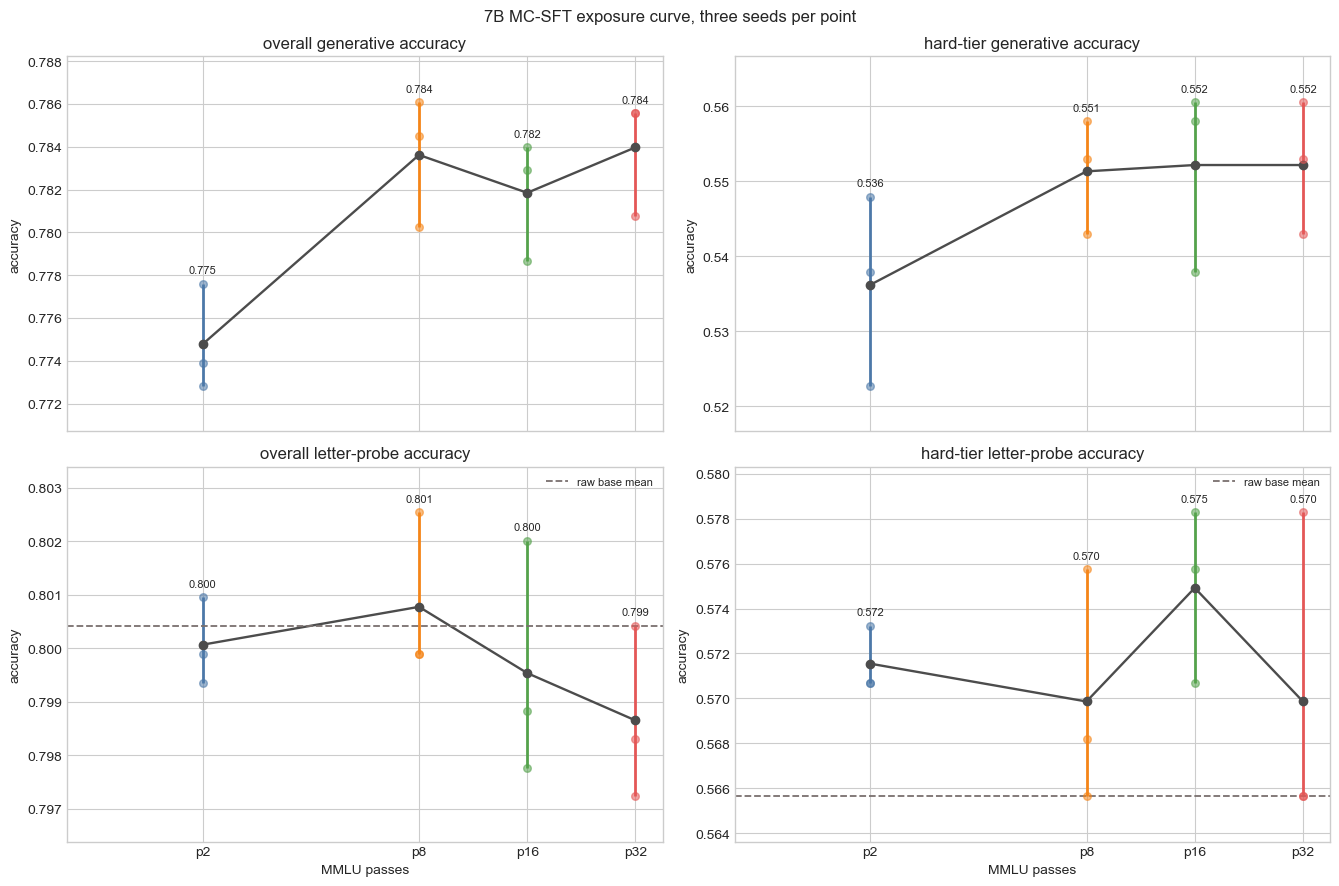

overall generative                 hard generative                  \
                       mean     min     max            mean     min     max   
exposure                                                                      
p2                   0.7748  0.7728  0.7776          0.5362  0.5227  0.5480   
p8                   0.7836  0.7803  0.7861          0.5513  0.5429  0.5581   
p16                  0.7818  0.7787  0.7840          0.5522  0.5379  0.5606   
p32                  0.7840  0.7808  0.7856          0.5522  0.5429  0.5606   

         overall probe                 hard probe                 hard margin  \
                  mean     min     max       mean     min     max        mean   
exposure                                                                        
p2              0.8001  0.7994  0.8010     0.5715  0.5707  0.5732     -0.0354   
p8              0.8008  0.7999  0.8025     0.5699  0.5657  0.5758     -0.0185   
p16             0.7995  0.7978  0.8020     0.5749  0.5707  0.5783     -0.0227   
p32             0.7987  0.7972  0.8004     0.5699  0.5657  0.5783     -0.0177   

                          
             min     max  
exposure                  
p2       -0.0505 -0.0227  
p8       -0.0328 -0.0101  
p16      -0.0328 -0.0177  
p32      -0.0227 -0.0126

In [4]:
# build the complete p2, p8, p16 and p32 endpoint table
curve_rows = []
for exposure in EXPOSURES:
    for seed, data in RUNS[exposure].items():
        curve_rows.append({
            'exposure': exposure,
            'passes': PASSES[exposure],
            'seed': seed,
            'overall generative': accuracy(data['preds']),
            'hard generative': data['eval']['per_tier_acc']['hard'],
            'overall probe': accuracy(data['probe_preds']),
            'hard probe': data['probe']['per_tier_acc']['hard'],
            'hard margin': (
                data['eval']['per_tier_acc']['hard']
                - data['probe']['per_tier_acc']['hard']
            ),
        })
curve_tbl = pd.DataFrame(curve_rows)
curve_summary = (
    curve_tbl.groupby(['exposure', 'passes'])[
        ['overall generative', 'hard generative', 'overall probe', 'hard probe', 'hard margin']
    ]
    .agg(['mean', 'min', 'max'])
    .reset_index()
)

base_probe_overall = np.mean([
    arm['probe_acc'] - arm['probe_delta_vs_base']
    for arm in REGISTERED['arms']
    if arm['exposure'] == 'p2'
])
base_probe_hard = np.mean([
    arm['hard_probe'] - arm['hard_probe_delta_vs_base']
    for arm in REGISTERED['arms']
    if arm['exposure'] == 'p2'
])

fig, axes = plt.subplots(2, 2, figsize=(13.5, 9), sharex=True)
metrics = [
    ('overall generative', 'overall generative accuracy'),
    ('hard generative', 'hard-tier generative accuracy'),
    ('overall probe', 'overall letter-probe accuracy'),
    ('hard probe', 'hard-tier letter-probe accuracy'),
]
for ax, (metric, title) in zip(axes.flat, metrics):
    means = []
    for exposure in EXPOSURES:
        table = curve_tbl[curve_tbl['exposure'] == exposure]
        x = PASSES[exposure]
        values = table[metric].to_numpy()
        mean = values.mean()
        means.append(mean)
        ax.scatter(
            np.full(len(values), x),
            values,
            color=COLORS[exposure],
            alpha=0.55,
            s=30,
            zorder=3,
        )
        ax.vlines(
            x,
            values.min(),
            values.max(),
            color=COLORS[exposure],
            lw=2,
        )
        ax.annotate(
            f'{mean:.3f}', (x, values.max()), xytext=(0, 6),
            textcoords='offset points', ha='center', va='bottom', fontsize=8,
        )
    ax.plot(
        [PASSES[value] for value in EXPOSURES],
        means,
        color='#4C4C4C',
        marker='o',
        lw=1.7,
        zorder=2,
    )
    if metric == 'overall probe':
        ax.axhline(
            base_probe_overall,
            color='#79706E',
            ls='--',
            lw=1.3,
            label='raw base mean',
        )
        ax.legend(fontsize=8)
    if metric == 'hard probe':
        ax.axhline(
            base_probe_hard,
            color='#79706E',
            ls='--',
            lw=1.3,
            label='raw base mean',
        )
        ax.legend(fontsize=8)
    ax.margins(y=0.16)
    ax.set_xscale('log', base=2)
    ax.set_xticks([2, 8, 16, 32])
    ax.set_xticklabels(['p2', 'p8', 'p16', 'p32'])
    ax.set_ylabel('accuracy')
    ax.set_title(title)

for ax in axes[1]:
    ax.set_xlabel('MMLU passes')
fig.suptitle('7B MC-SFT exposure curve, three seeds per point')
fig.tight_layout()
save(fig, 'fig02_exposure_curve')
plt.show()

display(
    curve_tbl.groupby('exposure')[[
        'overall generative',
        'hard generative',
        'overall probe',
        'hard probe',
        'hard margin',
    ]].agg(['mean', 'min', 'max']).loc[list(EXPOSURES)].round(4)
)


## 4. Cross-scale exposure context

This descriptive plot uses seed 0 at every scale because the earlier exposure sweeps only generatively evaluated seed 0 at both ends. Each point is shown relative to the p8 endpoint from the same scale and seed, so model capability does not dominate the vertical axis.


saved fig03_cross_scale_context


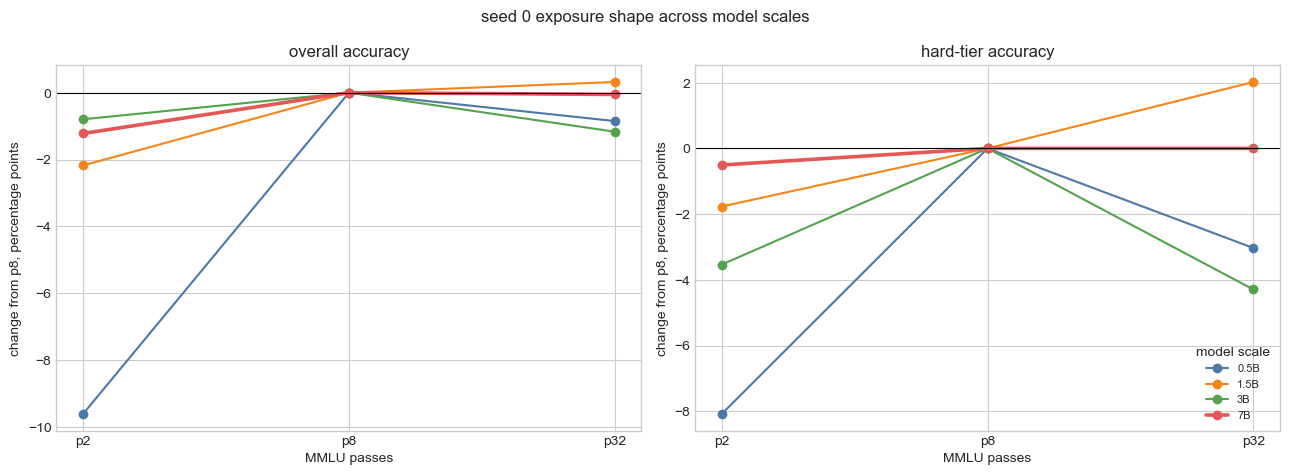

overall delta from p8              hard delta from p8             
exposure                    p2     p32   p8                 p2     p32   p8
scale                                                                      
0.5B                   -0.0961 -0.0085  0.0            -0.0808 -0.0303  0.0
1.5B                   -0.0218  0.0032  0.0            -0.0177  0.0202  0.0
3B                     -0.0080 -0.0117  0.0            -0.0354 -0.0429  0.0
7B                     -0.0122 -0.0005  0.0            -0.0051  0.0000  0.0

In [5]:
# compare the seed 0 exposure shape across all tested model scales
scale_paths = {
    '0.5B': {
        exposure: RES / f'007_{exposure}_COLAB_FULL_B05_sft_only_seed0'
        for exposure in ('p2', 'p8', 'p32')
    },
    '1.5B': {
        exposure: RES / f'010_{exposure}_COLAB_FULL_B15_sft_only_seed0'
        for exposure in ('p2', 'p8', 'p32')
    },
    '3B': {
        exposure: RES / f'007_{exposure}_COLAB_FULL_B3_sft_only_seed0'
        for exposure in ('p2', 'p8', 'p32')
    },
    '7B': {
        'p2': PATHS['p2'][0],
        'p8': PATHS['p8'][0],
        'p32': PATHS['p32'][0],
    },
}

cross_scale_rows = []
for scale, exposures in scale_paths.items():
    values = {}
    for exposure, path in exposures.items():
        eval_data = jload(path / 'sft_eval.json')
        pred_rows = jsonl(path / 'sft_preds.jsonl')
        values[exposure] = {
            'overall': accuracy(pred_rows),
            'hard': eval_data['per_tier_acc']['hard'],
        }
    for exposure in ('p2', 'p8', 'p32'):
        cross_scale_rows.append({
            'scale': scale,
            'exposure': exposure,
            'passes': PASSES[exposure],
            'overall delta from p8': (
                values[exposure]['overall'] - values['p8']['overall']
            ),
            'hard delta from p8': (
                values[exposure]['hard'] - values['p8']['hard']
            ),
        })
cross_scale_tbl = pd.DataFrame(cross_scale_rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharex=True)
for scale in SCALE_COLORS:
    table = (
        cross_scale_tbl[cross_scale_tbl['scale'] == scale]
        .sort_values('passes')
    )
    for metric, ax in [
        ('overall delta from p8', axes[0]),
        ('hard delta from p8', axes[1]),
    ]:
        ax.plot(
            table['passes'],
            table[metric] * 100,
            marker='o',
            lw=2.6 if scale == '7B' else 1.5,
            color=SCALE_COLORS[scale],
            label=scale,
        )
for ax, title in zip(axes, ['overall accuracy', 'hard-tier accuracy']):
    ax.axhline(0, color='black', lw=0.8)
    ax.set_xscale('log', base=2)
    ax.set_xticks([2, 8, 32])
    ax.set_xticklabels(['p2', 'p8', 'p32'])
    ax.set_xlabel('MMLU passes')
    ax.set_ylabel('change from p8, percentage points')
    ax.set_title(title)
axes[1].legend(title='model scale', fontsize=8)
fig.suptitle('seed 0 exposure shape across model scales')
fig.tight_layout()
save(fig, 'fig03_cross_scale_context')
plt.show()

display(
    cross_scale_tbl.pivot(
        index='scale',
        columns='exposure',
        values=['overall delta from p8', 'hard delta from p8'],
    ).round(4)
)


## 5. Registered comparisons

The shaded area is the registered plus or minus 2 percentage point equivalence region. Intervals are paired bootstrap intervals over the same 1,884 items. The printed classifications use the binding Holm-gated rule from the experiment, not the interval alone.


In [6]:
# collect the registered effects and matched endpoints
effect_rows = []
endpoint_rows = []
for arm in REGISTERED['arms']:
    exposure = arm['exposure']
    seed = arm['seed']
    values = arm['vs_p8']
    effect_rows.append({
        'comparison': f'{exposure} minus p8',
        'exposure': exposure,
        'seed': seed,
        'reference': values['reference_acc'],
        'new': values['new_acc'],
        'delta': values['delta'],
        'ci low': values['ci'][0],
        'ci high': values['ci'][1],
        'raw p': values['p_raw'],
        'Holm p': values['holm_p'],
        'classification': values['category'],
    })
    endpoint_rows.extend([
        {
            'comparison': exposure,
            'seed': seed,
            'endpoint': 'p8',
            'accuracy': values['reference_acc'],
        },
        {
            'comparison': exposure,
            'seed': seed,
            'endpoint': exposure,
            'accuracy': values['new_acc'],
        },
    ])

effect_tbl = pd.DataFrame(effect_rows)
endpoint_tbl = pd.DataFrame(endpoint_rows)
display(effect_tbl.set_index(['comparison', 'seed']).round(6))
print('p2 common reading:', REGISTERED['common_readings']['p2'])
print('p32 common reading:', REGISTERED['common_readings']['p32'])


exposure  reference       new     delta    ci low   ci high  \
comparison   seed                                                               
p2 minus p8  0          p2   0.786093  0.773885 -0.012208 -0.023355 -0.000531   
             1          p2   0.780255  0.772824 -0.007431 -0.018047  0.002654   
             2          p2   0.784501  0.777601 -0.006900 -0.018047  0.004246   
p32 minus p8 0         p32   0.786093  0.785563 -0.000531 -0.009023  0.007431   
             1         p32   0.780255  0.785563  0.005308 -0.002654  0.013800   
             2         p32   0.784501  0.780786 -0.003715 -0.012739  0.005839   

                      raw p    Holm p classification  
comparison   seed                                     
p2 minus p8  0     0.043268  0.129805   inconclusive  
             1     0.188847  0.377693     equivalent  
             2     0.267182  0.377693     equivalent  
p32 minus p8 0     1.000000  1.000000     equivalent  
             1     0.267812  0.803435     equivalent  
             2     0.499897  0.999794     equivalent

p2 common reading: mixed or inconclusive, report arm by arm
p32 common reading: equivalent


saved fig04_registered_effects


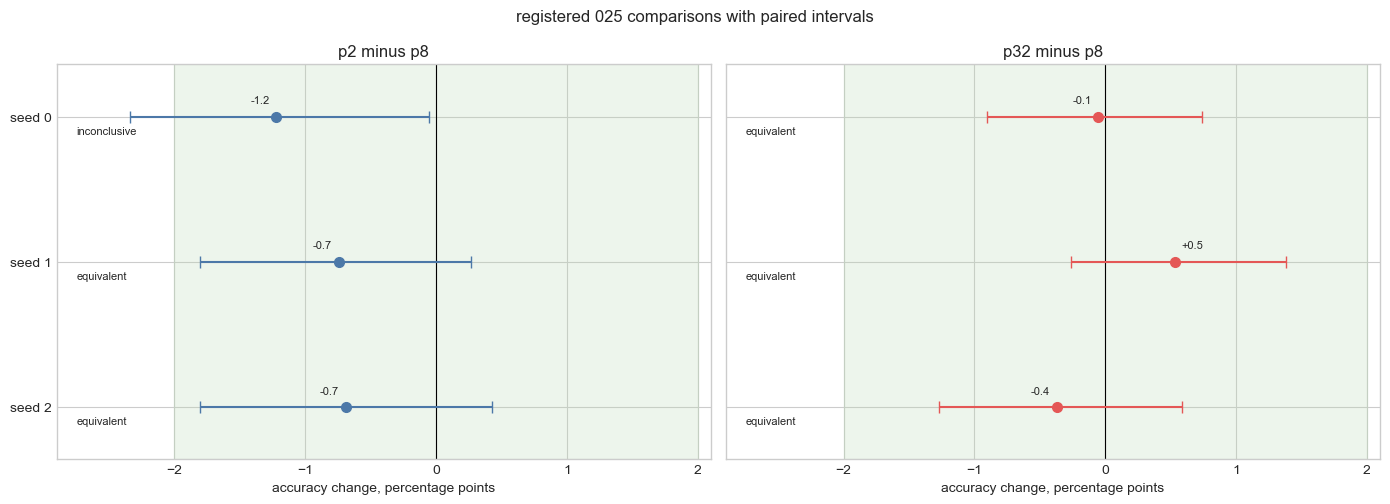

In [7]:
# plot the binding effects on one shared scale
comparisons = ['p2 minus p8', 'p32 minus p8']
fig, axes = plt.subplots(1, 2, figsize=(14, 5.1), sharex=True, sharey=True)

for ax, comparison in zip(axes, comparisons):
    table = effect_tbl.query('comparison == @comparison').sort_values('seed')
    y = np.arange(len(table))
    values = table['delta'].to_numpy() * 100
    errors = np.vstack([
        values - table['ci low'].to_numpy() * 100,
        table['ci high'].to_numpy() * 100 - values,
    ])
    exposure = table['exposure'].iloc[0]
    ax.axvspan(-2, 2, color='#B9D8B4', alpha=0.25)
    ax.axvline(0, color='black', lw=0.8)
    ax.errorbar(
        values,
        y,
        xerr=errors,
        fmt='o',
        capsize=4,
        color=COLORS[exposure],
        markersize=7,
    )
    for position, (_, row) in zip(y, table.iterrows()):
        ax.annotate(
            row['classification'], (-2.75, position), xytext=(0, -7),
            textcoords='offset points', ha='left', va='top', fontsize=8,
        )
        ax.annotate(
            f"{row['delta'] * 100:+.1f}", (row['delta'] * 100, position), xytext=(5 if row['delta'] >= 0 else -5, 8),
            textcoords='offset points', ha='left' if row['delta'] >= 0 else 'right',
            va='bottom', fontsize=8,
        )
    ax.margins(y=0.18)
    ax.set_yticks(y)
    ax.set_yticklabels([f'seed {seed}' for seed in table['seed']])
    ax.set_xlim(-2.9, 2.1)
    ax.set_xlabel('accuracy change, percentage points')
    ax.set_title(comparison)

axes[0].invert_yaxis()
fig.suptitle('registered 025 comparisons with paired intervals')
fig.tight_layout()
save(fig, 'fig04_registered_effects')
plt.show()


saved fig05_matched_endpoints


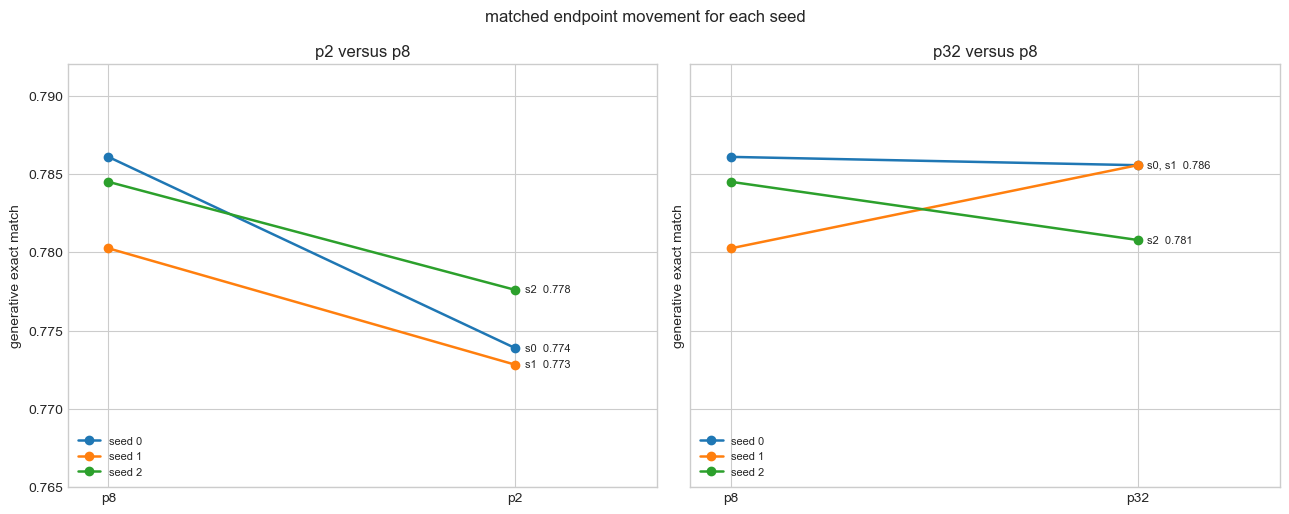

In [8]:
# show each seed moving from p8 to the matched exposure endpoint
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
for ax, exposure in zip(axes, NEW_EXPOSURES):
    table = endpoint_tbl[endpoint_tbl['comparison'] == exposure]
    endpoint_order = ['p8', exposure]
    for seed in SEEDS:
        values = (
            table[table['seed'] == seed]
            .set_index('endpoint')
            .loc[endpoint_order, 'accuracy']
            .to_numpy()
        )
        ax.plot(
            [0, 1],
            values,
            marker='o',
            lw=1.8,
            label=f'seed {seed}',
        )
    endpoints = table[table['endpoint'] == exposure]
    for value, rows in endpoints.groupby('accuracy'):
        seeds = ', '.join(f's{seed}' for seed in rows['seed'])
        ax.annotate(
            f'{seeds}  {value:.3f}', (1, value), xytext=(7, 0),
            textcoords='offset points', va='center', fontsize=8,
        )
    ax.set_xticks([0, 1])
    ax.set_xticklabels(endpoint_order)
    ax.set_xlim(-0.1, 1.35)
    ax.set_ylabel('generative exact match')
    ax.set_title(f'{exposure} versus p8')
    ax.legend(fontsize=8, loc='lower left')

axes[0].set_ylim(0.765, 0.792)
fig.suptitle('matched endpoint movement for each seed')
fig.tight_layout()
save(fig, 'fig05_matched_endpoints')
plt.show()


## 6. Tier pattern

The same registered comparisons are split by the easy, medium and hard tiers. Overall is included at the right so each tier result can be read beside the headline effect.


group                easy  medium    hard  overall
comparison   seed                                 
p2 minus p8  0    -0.0125 -0.0164 -0.0051  -0.0122
             1    -0.0023 -0.0066 -0.0202  -0.0074
             2     0.0000 -0.0082 -0.0202  -0.0069
p32 minus p8 0    -0.0068  0.0082  0.0000  -0.0005
             1     0.0046  0.0099  0.0000   0.0053
             2    -0.0091  0.0000  0.0025  -0.0037

saved fig06_tier_effects


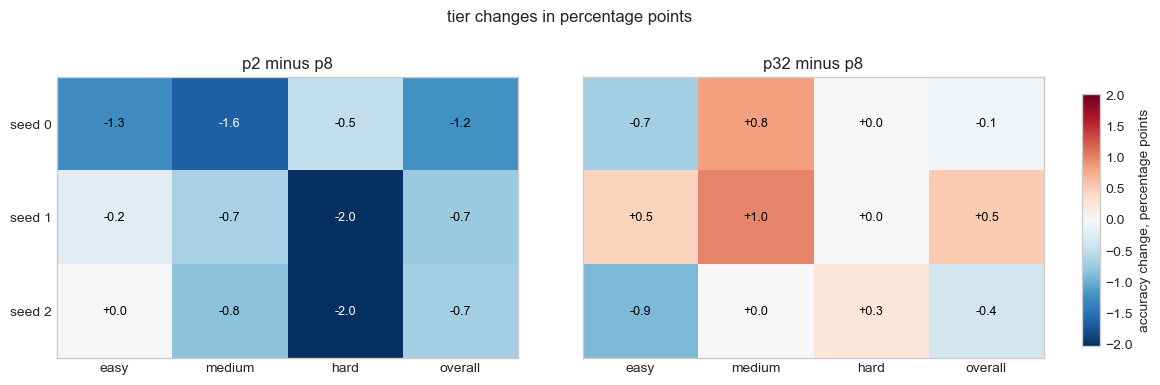

In [9]:
# locate the registered p2 and p32 changes across tiers
tier_rows = []
for exposure in NEW_EXPOSURES:
    for seed in SEEDS:
        new_data = RUNS[exposure][seed]
        reference_data = RUNS['p8'][seed]
        for tier in TIERS:
            tier_rows.append({
                'comparison': f'{exposure} minus p8',
                'seed': seed,
                'group': tier,
                'delta': (
                    new_data['eval']['per_tier_acc'][tier]
                    - reference_data['eval']['per_tier_acc'][tier]
                ),
            })
        tier_rows.append({
            'comparison': f'{exposure} minus p8',
            'seed': seed,
            'group': 'overall',
            'delta': (
                accuracy(new_data['preds'])
                - accuracy(reference_data['preds'])
            ),
        })
tier_tbl = pd.DataFrame(tier_rows)
display(tier_tbl.pivot_table(
    index=['comparison', 'seed'],
    columns='group',
    values='delta',
)[GROUPS].round(4))

limit = max(abs(tier_tbl['delta'].min()), abs(tier_tbl['delta'].max())) * 100
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), sharey=True)
for ax, comparison in zip(axes, comparisons):
    matrix = (
        tier_tbl[tier_tbl['comparison'] == comparison]
        .pivot(index='seed', columns='group', values='delta')
        .loc[list(SEEDS), GROUPS]
        .to_numpy() * 100
    )
    image = ax.imshow(
        matrix,
        cmap='RdBu_r',
        norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit),
        aspect='auto',
        interpolation='nearest',
    )
    ax.grid(False)
    for row in range(matrix.shape[0]):
        for col in range(matrix.shape[1]):
            color = heatmap_text_color(image, matrix[row, col])
            ax.text(
                col,
                row,
                f'{matrix[row, col]:+.1f}',
                ha='center',
                va='center',
                color=color,
                fontsize=9,
            )
    ax.set_xticks(np.arange(len(GROUPS)))
    ax.set_xticklabels(GROUPS)
    ax.set_yticks(np.arange(len(SEEDS)))
    ax.set_yticklabels([f'seed {seed}' for seed in SEEDS])
    ax.set_title(comparison)

fig.suptitle('tier changes in percentage points')
fig.subplots_adjust(left=0.09, right=0.88, bottom=0.15, top=0.82, wspace=0.14)
colorbar_ax = fig.add_axes([0.91, 0.18, 0.015, 0.60])
fig.colorbar(image, cax=colorbar_ax, label='accuracy change, percentage points')
save(fig, 'fig06_tier_effects')
plt.show()


## 7. Subject pattern

The subject matrices use one shared colour scale. The final column is the mean change across seeds and the horizontal lines follow the validated tier mapping.


comparison                      p2 minus p8  p32 minus p8
tier   subject                                           
easy   high_school_psychology       -0.0073        0.0012
       marketing                    -0.0014       -0.0085
       us_foreign_policy             0.0000       -0.0200
hard   formal_logic                 -0.0053        0.0000
       high_school_mathematics      -0.0198        0.0012
medium business_ethics              -0.0167        0.0067
       high_school_geography        -0.0034       -0.0017
       philosophy                   -0.0129        0.0107

saved fig07_subject_effects


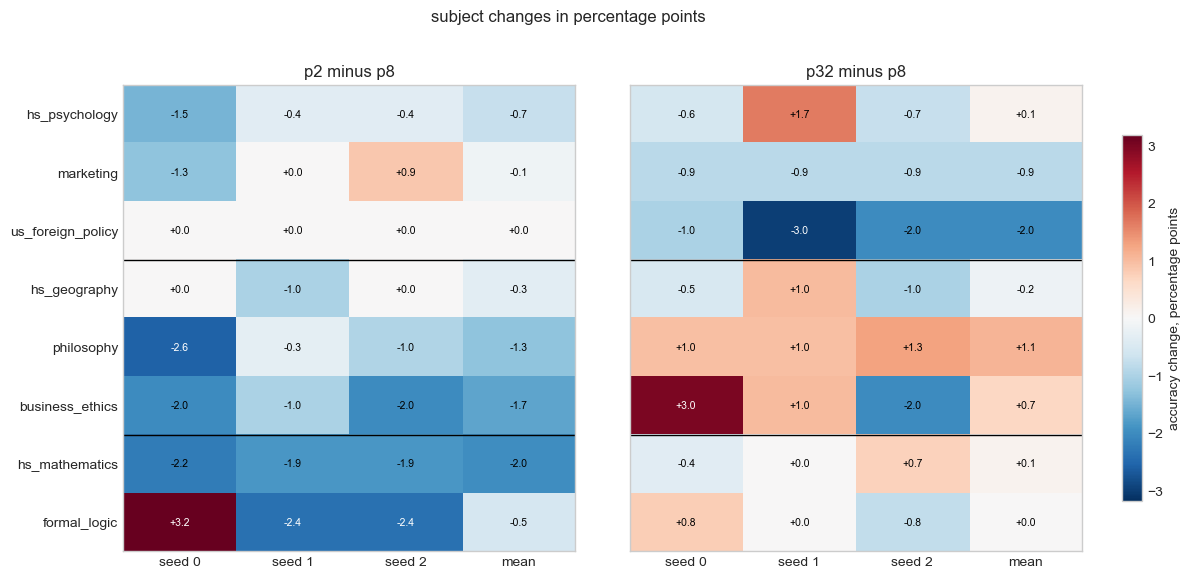

In [10]:
# compare subject changes for both registered questions
subject_rows = []
for exposure in NEW_EXPOSURES:
    for seed in SEEDS:
        for subject in SUBJECTS:
            subject_rows.append({
                'comparison': f'{exposure} minus p8',
                'seed': seed,
                'subject': subject,
                'tier': TIER_LOOKUP[subject],
                'delta': (
                    RUNS[exposure][seed]['eval']['per_subject_acc'][subject]
                    - RUNS['p8'][seed]['eval']['per_subject_acc'][subject]
                ),
            })
subject_tbl = pd.DataFrame(subject_rows)
subject_mean_tbl = (
    subject_tbl.groupby(['comparison', 'subject', 'tier'], as_index=False)['delta']
    .mean()
    .rename(columns={'delta': 'mean delta'})
)
display(subject_mean_tbl.pivot(
    index=['tier', 'subject'],
    columns='comparison',
    values='mean delta',
).round(4))

matrix_values = []
for comparison in comparisons:
    pivot = (
        subject_tbl[subject_tbl['comparison'] == comparison]
        .pivot(index='subject', columns='seed', values='delta')
        .loc[SUBJECTS, list(SEEDS)]
    )
    matrix_values.append(
        np.column_stack([pivot.to_numpy(), pivot.mean(axis=1)]) * 100
    )
subject_limit = max(
    abs(np.concatenate(matrix_values).min()),
    abs(np.concatenate(matrix_values).max()),
)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 6.3), sharey=True)
for ax, comparison, matrix in zip(axes, comparisons, matrix_values):
    image = ax.imshow(
        matrix,
        cmap='RdBu_r',
        norm=TwoSlopeNorm(vmin=-subject_limit, vcenter=0, vmax=subject_limit),
        aspect='auto',
        interpolation='nearest',
    )
    ax.grid(False)
    for row in range(matrix.shape[0]):
        for col in range(matrix.shape[1]):
            color = heatmap_text_color(image, matrix[row, col])
            ax.text(
                col,
                row,
                f'{matrix[row, col]:+.1f}',
                ha='center',
                va='center',
                color=color,
                fontsize=7.5,
            )
    ax.set_xticks(np.arange(4))
    ax.set_xticklabels(['seed 0', 'seed 1', 'seed 2', 'mean'])
    ax.set_yticks(np.arange(len(SUBJECTS)))
    ax.set_yticklabels([
        subject.replace('high_school_', 'hs_')
        for subject in SUBJECTS
    ])
    easy_end = len(VALIDATED_TIERS['easy']) - 0.5
    medium_end = len(VALIDATED_TIERS['easy']) + len(VALIDATED_TIERS['medium']) - 0.5
    ax.axhline(easy_end, color='black', lw=1)
    ax.axhline(medium_end, color='black', lw=1)
    ax.set_title(comparison)

fig.suptitle('subject changes in percentage points')
fig.subplots_adjust(left=0.17, right=0.88, bottom=0.12, top=0.86, wspace=0.12)
colorbar_ax = fig.add_axes([0.91, 0.20, 0.015, 0.58])
fig.colorbar(image, cax=colorbar_ax, label='accuracy change, percentage points')
save(fig, 'fig07_subject_effects')
plt.show()


## 8. Paired item changes

The net score can hide movement in both directions. These panels count matched test items that only p8 answered correctly and items that only the new exposure answered correctly.


p8 only correct  new only correct  net items
comparison   seed                                              
p2 minus p8  0                  71                48        -23
             1                  56                42        -14
             2                  65                52        -13
p32 minus p8 0                  33                32         -1
             1                  28                38         10
             2                  43                36         -7

saved fig08_paired_transitions


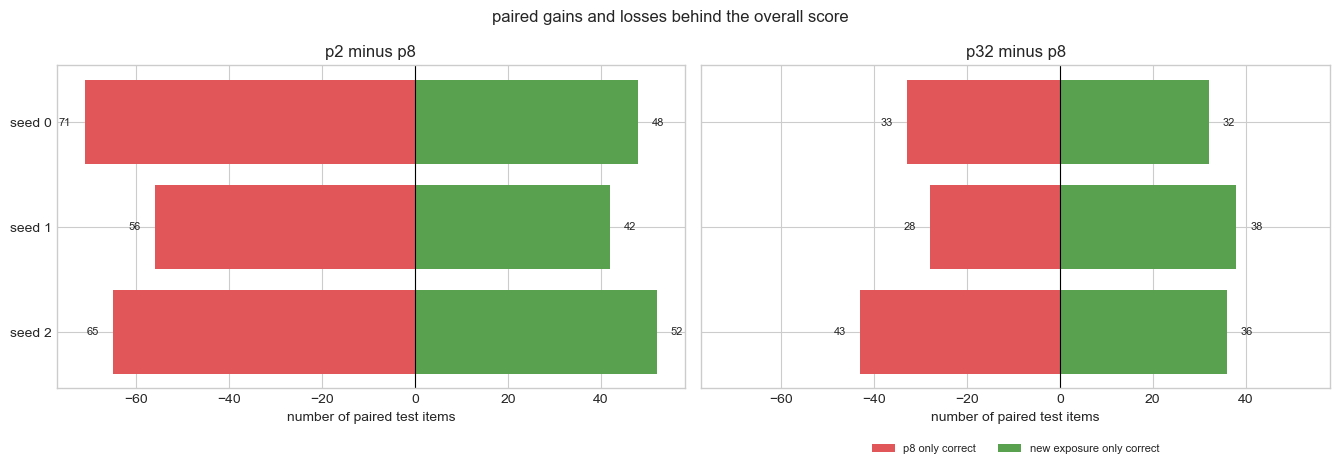

In [11]:
# count paired gains and losses behind each overall effect
transition_rows = []
for exposure in NEW_EXPOSURES:
    comparison = f'{exposure} minus p8'
    for seed in SEEDS:
        reference_rows, new_rows = align_pred_rows(
            RUNS['p8'][seed]['preds'],
            RUNS[exposure][seed]['preds'],
        )
        reference_correct = np.asarray([
            bool(row['correct']) for row in reference_rows
        ])
        new_correct = np.asarray([
            bool(row['correct']) for row in new_rows
        ])
        reference_only = int(np.sum(reference_correct & ~new_correct))
        new_only = int(np.sum(~reference_correct & new_correct))
        transition_rows.append({
            'comparison': comparison,
            'seed': seed,
            'p8 only correct': reference_only,
            'new only correct': new_only,
            'net items': new_only - reference_only,
        })
transition_tbl = pd.DataFrame(transition_rows)
display(transition_tbl.set_index(['comparison', 'seed']))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), sharex=True, sharey=True)
for ax, comparison in zip(axes, comparisons):
    table = transition_tbl[transition_tbl['comparison'] == comparison].sort_values('seed')
    y = np.arange(len(table))
    losses = -table['p8 only correct'].to_numpy()
    gains = table['new only correct'].to_numpy()
    ax.barh(y, losses, color='#E15759', label='p8 only correct')
    ax.barh(y, gains, color='#59A14F', label='new exposure only correct')
    for position, loss, gain in zip(y, -losses, gains):
        ax.text(-loss - 3, position, str(loss), ha='right', va='center', fontsize=8)
        ax.text(gain + 3, position, str(gain), ha='left', va='center', fontsize=8)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels([f'seed {seed}' for seed in table['seed']])
    ax.set_xlabel('number of paired test items')
    ax.set_title(comparison)

axes[0].invert_yaxis()
axes[1].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2)
fig.suptitle('paired gains and losses behind the overall score')
fig.tight_layout()
save(fig, 'fig08_paired_transitions')
plt.show()


## 9. Probe erosion and generative margin

The letter probe is separate from free generation. Stable probe accuracy with a different generative score is evidence about elicitation under this protocol, not proof that factual knowledge was added or removed.


,,,delta,ci low,ci high,classification
group,exposure,seed,,,,
overall,p2,0,-0.001062,-0.006369,0.004246,unchanged (equivalence rule met)
hard,p2,0,0.005051,-0.012626,0.022727,equivalence not established
overall,p2,1,0.000531,-0.005308,0.006369,unchanged (equivalence rule met)
hard,p2,1,0.007576,-0.012626,0.027778,equivalence not established
overall,p2,2,-0.000531,-0.005839,0.004777,unchanged (equivalence rule met)
hard,p2,2,0.005051,-0.012626,0.022727,equivalence not established
overall,p32,0,-0.002123,-0.009554,0.005839,unchanged (equivalence rule met)
hard,p32,0,0.000000,-0.027778,0.027778,equivalence not established
overall,p32,1,-0.003185,-0.011146,0.005308,unchanged (equivalence rule met)


saved fig09_probe_and_generation


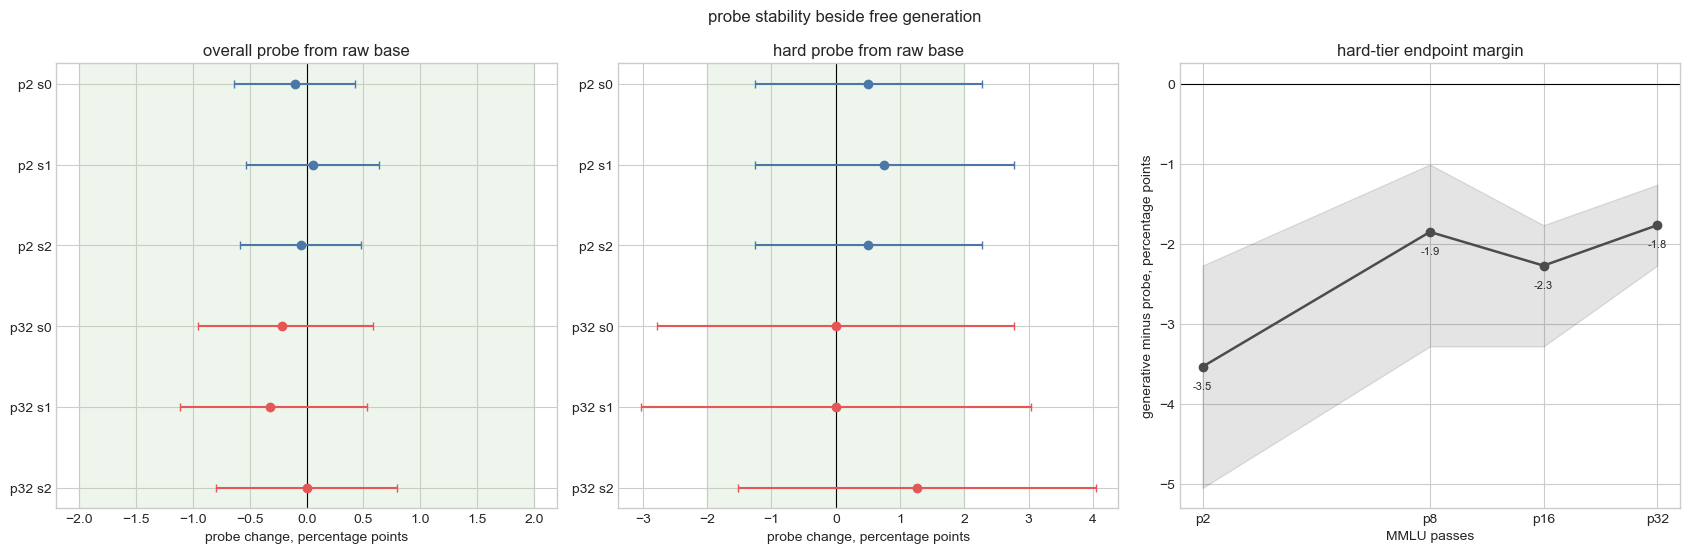

In [12]:
# compare probe changes from raw base and the hard generative margin
probe_rows = []
for arm in REGISTERED['arms']:
    for group, delta_key, ci_key, class_key in [
        ('overall', 'probe_delta_vs_base', 'probe_ci', 'probe_class'),
        ('hard', 'hard_probe_delta_vs_base', 'hard_probe_ci', 'hard_probe_class'),
    ]:
        probe_rows.append({
            'exposure': arm['exposure'],
            'seed': arm['seed'],
            'group': group,
            'delta': arm[delta_key],
            'ci low': arm[ci_key][0],
            'ci high': arm[ci_key][1],
            'classification': arm[class_key],
        })
probe_tbl = pd.DataFrame(probe_rows)
display(probe_tbl.set_index(['group', 'exposure', 'seed']).round(6))

fig, axes = plt.subplots(1, 3, figsize=(17, 5.6))
for ax, group in zip(axes[:2], ['overall', 'hard']):
    table = probe_tbl[probe_tbl['group'] == group].copy()
    table['label'] = table.apply(
        lambda row: f"{row['exposure']} s{row['seed']}",
        axis=1,
    )
    y = np.arange(len(table))
    values = table['delta'].to_numpy() * 100
    errors = np.vstack([
        values - table['ci low'].to_numpy() * 100,
        table['ci high'].to_numpy() * 100 - values,
    ])
    ax.axvspan(-2, 2, color='#B9D8B4', alpha=0.25)
    ax.axvline(0, color='black', lw=0.8)
    for position, (_, row), error in zip(y, table.iterrows(), errors.T):
        ax.errorbar(
            row['delta'] * 100,
            position,
            xerr=np.asarray(error).reshape(2, 1),
            fmt='o',
            capsize=3,
            color=COLORS[row['exposure']],
        )
    ax.set_yticks(y)
    ax.set_yticklabels(table['label'])
    ax.invert_yaxis()
    ax.set_xlabel('probe change, percentage points')
    ax.set_title(f'{group} probe from raw base')

margin_summary = (
    curve_tbl.groupby(['exposure', 'passes'])['hard margin']
    .agg(['mean', 'min', 'max'])
    .reset_index()
    .sort_values('passes')
)
axes[2].axhline(0, color='black', lw=0.8)
axes[2].plot(
    margin_summary['passes'],
    margin_summary['mean'] * 100,
    color='#4C4C4C',
    marker='o',
    lw=1.8,
)
axes[2].fill_between(
    margin_summary['passes'],
    margin_summary['min'] * 100,
    margin_summary['max'] * 100,
    color='#4C4C4C',
    alpha=0.15,
)
for _, row in margin_summary.iterrows():
    axes[2].text(
        row['passes'],
        row['mean'] * 100 - 0.18,
        f"{row['mean'] * 100:+.1f}",
        ha='center',
        va='top',
        fontsize=8,
    )
axes[2].set_xscale('log', base=2)
axes[2].set_xticks([2, 8, 16, 32])
axes[2].set_xticklabels(['p2', 'p8', 'p16', 'p32'])
axes[2].set_xlabel('MMLU passes')
axes[2].set_ylabel('generative minus probe, percentage points')
axes[2].set_title('hard-tier endpoint margin')

fig.suptitle('probe stability beside free generation')
fig.tight_layout()
save(fig, 'fig09_probe_and_generation')
plt.show()


## 10. Exact values

The tables below are saved beside the figures so the plotted values can be reused without reading them from the images.


In [13]:
# save the exact values used by the figures
health_tbl.reset_index().to_csv(FIG / '025_1_run_health.csv', index=False)
train_tbl.to_csv(FIG / '025_1_training_curves.csv', index=False)
curve_tbl.to_csv(FIG / '025_1_exposure_curve.csv', index=False)
cross_scale_tbl.to_csv(FIG / '025_1_cross_scale_context.csv', index=False)
effect_tbl.to_csv(FIG / '025_1_registered_effects.csv', index=False)
endpoint_tbl.to_csv(FIG / '025_1_endpoints.csv', index=False)
tier_tbl.to_csv(FIG / '025_1_tier_effects.csv', index=False)
subject_tbl.to_csv(FIG / '025_1_subject_effects.csv', index=False)
transition_tbl.to_csv(FIG / '025_1_paired_transitions.csv', index=False)
probe_tbl.to_csv(FIG / '025_1_probe_effects.csv', index=False)

headline = effect_tbl.copy()
headline['reference'] = (headline['reference'] * 100).round(2)
headline['new'] = (headline['new'] * 100).round(2)
headline['delta'] = (headline['delta'] * 100).round(2)
headline['95% interval'] = effect_tbl.apply(
    lambda row: f"[{row['ci low'] * 100:+.2f}, {row['ci high'] * 100:+.2f}]",
    axis=1,
)
display(headline[[
    'comparison',
    'seed',
    'reference',
    'new',
    'delta',
    '95% interval',
    'Holm p',
    'classification',
]].set_index(['comparison', 'seed']))

print('saved exact tables ->', FIG.relative_to(ROOT))


reference    new  delta    95% interval    Holm p  \
comparison   seed                                                      
p2 minus p8  0         78.61  77.39  -1.22  [-2.34, -0.05]  0.129805   
             1         78.03  77.28  -0.74  [-1.80, +0.27]  0.377693   
             2         78.45  77.76  -0.69  [-1.80, +0.42]  0.377693   
p32 minus p8 0         78.61  78.56  -0.05  [-0.90, +0.74]  1.000000   
             1         78.03  78.56   0.53  [-0.27, +1.38]  0.803435   
             2         78.45  78.08  -0.37  [-1.27, +0.58]  0.999794   

                  classification  
comparison   seed                 
p2 minus p8  0      inconclusive  
             1        equivalent  
             2        equivalent  
p32 minus p8 0        equivalent  
             1        equivalent  
             2        equivalent

saved exact tables -> analysis/figures/025_1


## Cross-referenced conclusion

All six new 025 arms completed cleanly on A100 80GB with the declared p2 and p32 configurations. The schedules covered every registered step, both evaluation modes used 1,884 items and no fallback was used. Format compliance was 1.0 in five arms and 0.994 in p2 seed 2, with no extraction failures.

The 7B base MC-SFT curve rises from a p2 mean of 77.48% to 78.36% at p8, then stays almost flat at 78.18% for p16 and 78.40% for p32. P32 was equivalent to p8 in all three matched seeds. P2 was 0.7 to 1.2 points below p8: seeds 1 and 2 were equivalent, while seed 0 remained inconclusive after Holm correction. The registered p2 reading therefore stays mixed and must be reported arm by arm.

Hard-tier means follow the same pattern: 53.62% at p2 and about 55.2% at p8, p16 and p32. Overall probe accuracy stayed close to 80% across the curve. P32 does not show the 3 to 6 point hard-probe erosion seen at 0.5B, although the hard-tier intervals are too wide to establish equivalence for each seed.

Generative hard accuracy remained below the letter probe at every 7B exposure. The mean gap was -3.5 points at p2 and about -1.8 to -2.3 points from p8 onward. Longer MC-SFT therefore did not remove the remaining hard-tier elicitation gap.

The seed 0 cross-scale context shows that p2 was especially weak at 0.5B, while the 7B p32 endpoint was nearly identical to p8. This supports a flatter useful budget region at 7B after p8, but the comparison remains descriptive because earlier exposure ends were only generatively evaluated for seed 0 and every budget used its own decay schedule.
